# 03 · Obesidad: exploración de datos

Proyecto del curso Machine Learning (650064), Universidad de Lima, ciclo 2026-2.  
**Objetivo del notebook:** describir el dataset, revisar faltantes y duplicados, fijar la partición train/test y verificar en los datos las trampas que condicionan el modelado.  
**Decisiones:** `documentacion/diseno_experimental.md` (las secciones del diseño se citan como §).

## Autores por sección

| Sección | Autor |
|---|---|
| Todas las secciones de este notebook | Eros Bellido |
| Funciones de `utilidades.py` | Marcelo Cueto |

## 0. Configuración

**Qué hacemos:** preparamos el entorno y cargamos las librerías.

**Por qué:** la celda 0 hace que el mismo notebook funcione en VS Code y en Colab, con las versiones fijadas en `requirements.txt`.

In [1]:
# Celda 0. Configuración del entorno: funciona igual en VS Code y en Colab.
import os
import sys

EN_COLAB = "google.colab" in sys.modules
USUARIO_GITHUB = "MCuetoV"
REPOSITORIO = "proyecto-ml-2026-2"

if EN_COLAB:
    # En Colab: clonar el repositorio (o actualizarlo) con el token guardado en Secrets
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    if not os.path.exists(f"/content/{REPOSITORIO}"):
        !git clone -q https://{token}@github.com/{USUARIO_GITHUB}/{REPOSITORIO}.git /content/{REPOSITORIO}
    os.chdir(f"/content/{REPOSITORIO}")
    !git pull -q
    !pip install -q -r requirements.txt
else:
    # En VS Code: si el notebook se abrió desde notebooks/, subir a la raíz del repositorio
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2


In [2]:
# Librerías y funciones comunes del proyecto
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utilidades

pd.set_option("display.max_columns", 50)
print("Semilla del proyecto:", utilidades.SEMILLA)

Semilla del proyecto: 42


In [3]:
# Nombres cortos que se usan en todo el notebook
import numpy as np

OBJETIVO = utilidades.OBJETIVO_OBESIDAD
ORDEN = utilidades.ORDEN_OBESIDAD
NOMBRES_CLASES = {"Insufficient_Weight": "Peso insuficiente", "Normal_Weight": "Normal",
                  "Overweight_Level_I": "Sobrepeso I", "Overweight_Level_II": "Sobrepeso II",
                  "Obesity_Type_I": "Obesidad I", "Obesity_Type_II": "Obesidad II",
                  "Obesity_Type_III": "Obesidad III"}

## 1. Carga y descripción del dataset

**Qué hacemos:** cargamos los datos con los pasos determinísticos del diseño y describimos sus variables.

**Por qué:** la Experimentación del reporte empieza describiendo el dataset (consigna). `cargar_obesidad()` elimina duplicados, redondea a la precisión de la encuesta, fusiona CALC = "Always" con "Frequently" y crea las columnas auxiliares `probablemente_real` y `grupo` (diseño, §4.1); la sección 2 muestra el CSV original para justificar cada paso.

In [4]:
# Datos con los pasos determinísticos de §4.1
datos = utilidades.cargar_obesidad()
print("Filas y columnas:", datos.shape)
print(datos[OBJETIVO].value_counts().reindex(ORDEN))
datos.head()

Filas y columnas: (2087, 19)
NObeyesdad
Insufficient_Weight    267
Normal_Weight          282
Overweight_Level_I     276
Overweight_Level_II    290
Obesity_Type_I         351
Obesity_Type_II        297
Obesity_Type_III       324
Name: count, dtype: int64


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad,probablemente_real,grupo
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight,True,0
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight,True,1
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight,True,2
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I,True,3
4,Male,22.0,1.78,90.0,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II,True,4


**Qué observamos:** después de eliminar los 24 duplicados quedan 2087 personas y 16 variables de entrada, más las columnas auxiliares `probablemente_real` y `grupo`, que no entran al modelo. Las siete clases tienen entre 267 y 351 filas: el dataset está casi balanceado porque los autores lo sobremuestrearon con SMOTE. Las respuestas de la encuesta ya aparecen redondeadas (por ejemplo, FCVC = 2.0).

In [5]:
# Descripción de cada variable según el descriptor del dataset (Mendoza Palechor y De la Hoz Manotas, 2019)
DESCRIPCION = {
    "Gender": "Sexo", "Age": "Edad (años)", "Height": "Estatura (m)", "Weight": "Peso (kg)",
    "family_history_with_overweight": "Familiar con sobrepeso", "FAVC": "Consume alimentos hipercalóricos con frecuencia",
    "FCVC": "Frecuencia de consumo de verduras", "NCP": "Número de comidas principales al día",
    "CAEC": "Come entre comidas", "SMOKE": "Fuma", "CH2O": "Agua que bebe al día",
    "SCC": "Controla las calorías que consume", "FAF": "Frecuencia de actividad física",
    "TUE": "Tiempo de uso de dispositivos tecnológicos", "CALC": "Consumo de alcohol",
    "MTRANS": "Medio de transporte habitual"}

In [6]:
# Tipo de cada variable según cómo se codifica en el modelado (diseño, §4.2)
def tipo_de(variable):
    if variable in utilidades.BINARIAS_OBESIDAD: return "Binaria"
    if variable in utilidades.NOMINALES_OBESIDAD: return "Nominal"
    if variable in ["CAEC", "CALC"] + utilidades.ENCUESTA_OBESIDAD: return "Ordinal"
    return "Numérica"

def valores_de(variable):
    if datos[variable].dtype == object: return ", ".join(sorted(datos[variable].unique()))
    return f"{datos[variable].min():g} a {datos[variable].max():g}"

In [7]:
# Tabla 1 del reporte: una fila por variable
variables = utilidades.COLUMNAS_OBESIDAD
tabla_variables = pd.DataFrame({
    "variable": variables,
    "descripcion": [DESCRIPCION[v] for v in variables],
    "tipo": [tipo_de(v) for v in variables],
    "valores": [valores_de(v) for v in variables],
    "escenario": ["Solo E1" if v in utilidades.ANTROPOMETRIA else "E1 y E2" for v in variables]})
utilidades.guardar_tabla(tabla_variables, "tabla_01_descripcion_obesidad")
tabla_variables

,variable,descripcion,tipo,valores,escenario
0,Gender,Sexo,Binaria,"Female, Male",E1 y E2
1,Age,Edad (años),Numérica,14 a 61,E1 y E2
2,Height,Estatura (m),Numérica,1.45 a 1.98,Solo E1
3,Weight,Peso (kg),Numérica,39 a 173,Solo E1
4,family_history_with_overweight,Familiar con sobrepeso,Binaria,"no, yes",E1 y E2
5,FAVC,Consume alimentos hipercalóricos con frecuencia,Binaria,"no, yes",E1 y E2
6,FCVC,Frecuencia de consumo de verduras,Ordinal,1 a 3,E1 y E2
7,NCP,Número de comidas principales al día,Ordinal,1 a 4,E1 y E2
8,CAEC,Come entre comidas,Ordinal,"Always, Frequently, Sometimes, no",E1 y E2
9,SMOKE,Fuma,Binaria,"no, yes",E1 y E2


**Qué observamos:** de las 16 variables, 5 son binarias, 1 nominal (MTRANS), 7 ordinales (las cinco respuestas numéricas de la encuesta, más CAEC y CALC) y 3 numéricas (edad, estatura y peso). Height y Weight solo se usan en el escenario E1; el escenario principal E2 trabaja con las 14 restantes.

## 2. Valores faltantes, duplicados y huella de SMOTE

**Qué hacemos:** revisamos el CSV original: faltantes, filas repetidas y decimales en respuestas que la encuesta registra como enteros.

**Por qué:** la consigna pide revisar faltantes. Los duplicados podrían quedar a la vez en train y en test, y los decimales delatan las filas sintéticas que los autores generaron con SMOTE (diseño, §4.1).

In [8]:
# CSV original, antes de los pasos de §4.1
original = pd.read_csv("datos/ObesityDataSet_raw_and_data_sinthetic.csv")
print("Filas originales:", len(original))
print("Valores faltantes:", original.isna().sum().sum())
print("Filas duplicadas (copias exactas de otra fila):", original.duplicated().sum())

Filas originales: 2111
Valores faltantes: 0
Filas duplicadas (copias exactas de otra fila): 24


In [9]:
# Huella de SMOTE: en la encuesta real estas respuestas son enteras; las sintéticas traen decimales
ENTERAS = utilidades.ENCUESTA_OBESIDAD + ["Age"]
sin_duplicados = original.drop_duplicates()
tiene_decimales = ~np.isclose(sin_duplicados[ENTERAS], sin_duplicados[ENTERAS].round())
print("Filas con decimales en alguna de", ENTERAS, ":", tiene_decimales.any(axis=1).sum())
print("Filas probablemente reales (todo entero):", datos["probablemente_real"].sum(), "de", len(datos))
print("Ejemplo de valores sintéticos de FCVC:", sin_duplicados["FCVC"][tiene_decimales[:, 0]].head(3).tolist())

Filas con decimales en alguna de ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'Age'] : 1596
Filas probablemente reales (todo entero): 491 de 2087
Ejemplo de valores sintéticos de FCVC: [2.450218, 2.880161, 2.00876]


**Qué observamos:** el CSV original no tiene valores faltantes, pero sí 24 filas que son copias exactas de otra; se eliminan antes de dividir para que una misma respuesta no quede en train y en test. Además, 1596 de las 2087 filas restantes tienen decimales en respuestas que la encuesta registra como enteros (por ejemplo, FCVC = 2.45); son las filas que generó SMOTE. Quedan 491 filas probablemente reales, una cifra cercana a las 485 que declaran los autores; la diferencia sugiere que unas pocas filas sintéticas salieron con valores enteros por coincidencia.

## 3. Partición train/test

**Qué hacemos:** separamos el test de reserva (20%) con la función común, estratificada y agrupada.

**Por qué:** las filas idénticas tras el redondeo deben quedar del mismo lado; si no, el test contiene copias del train y las métricas se inflan (diseño, §7). El EDA que informa decisiones se hace solo con el train.

In [10]:
# Partición única del proyecto (§7): la misma que usa el notebook 04
train, test = utilidades.dividir_train_test(datos, "obesidad")
print("Train:", len(train), "· Test:", len(test), f"({len(test) / len(datos):.1%})")
print("Grupos compartidos entre train y test:", len(set(train["grupo"]) & set(test["grupo"])))
proporciones = pd.DataFrame({"train": train[OBJETIVO].value_counts(normalize=True),
                             "test": test[OBJETIVO].value_counts(normalize=True)}).reindex(ORDEN)
proporciones.round(3)

Train: 1671 · Test: 416 (19.9%)
Grupos compartidos entre train y test: 0


,train,test
NObeyesdad,,
Insufficient_Weight,0.128,0.127
Normal_Weight,0.135,0.137
Overweight_Level_I,0.132,0.132
Overweight_Level_II,0.139,0.139
Obesity_Type_I,0.168,0.171
Obesity_Type_II,0.142,0.142
Obesity_Type_III,0.156,0.151


**Qué observamos:** el test tiene 416 filas (19.9%) y ningún grupo de filas idénticas aparece a la vez en train y en test. Las proporciones de las siete clases difieren en 0.5 puntos porcentuales como máximo. Elegir el test con un criterio estructural importa: con la primera partición, toda la clase Obesity_Type_III del test era un único vector repetido 75 veces (diseño, §7).

## 4. Análisis univariante y del target (train)

**Qué hacemos:** describimos la distribución de las siete clases, de la edad, la estatura y el peso, y de las respuestas de la encuesta.

**Por qué:** el balance de clases define la métrica y la necesidad de remuestrear; las escalas y los niveles definen la codificación (diseño, §4.2, §5 y §9).

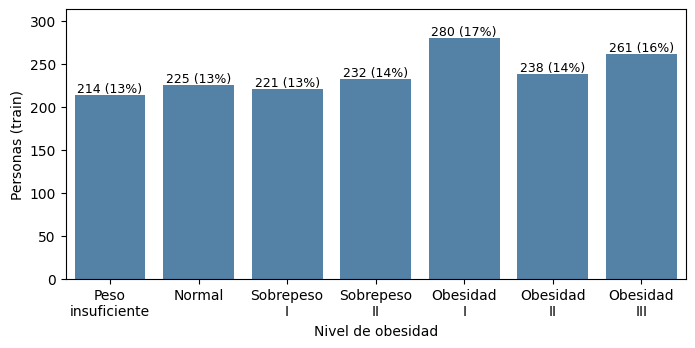

In [11]:
# Figura 2: distribución del target en el train, en orden de severidad
conteo = train[OBJETIVO].value_counts().reindex(ORDEN).rename(index=NOMBRES_CLASES)
figura, eje = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=conteo.index, y=conteo.values, color="steelblue", ax=eje)
for posicion, valor in enumerate(conteo.values):
    eje.text(posicion, valor, f"{valor} ({valor / conteo.sum():.0%})", ha="center", va="bottom", fontsize=9)
eje.set_xticks(range(len(conteo)), [n.replace(" ", "\n") for n in conteo.index])   # nombres en dos líneas
eje.set_xlabel("Nivel de obesidad")
eje.set_ylabel("Personas (train)")
eje.set_ylim(0, conteo.max() * 1.12)   # espacio para las etiquetas
utilidades.guardar_figura(figura, "figura_02_target_obesidad")
plt.show()

**Qué observamos:** en el train, las siete clases tienen entre 214 (13%) y 280 (17%) personas. Como no hay una clase dominante, no hace falta remuestrear (diseño, §5); el macro-F1 y el *accuracy* darán valores parecidos, y el kappa ponderado agrega la información del orden entre clases.

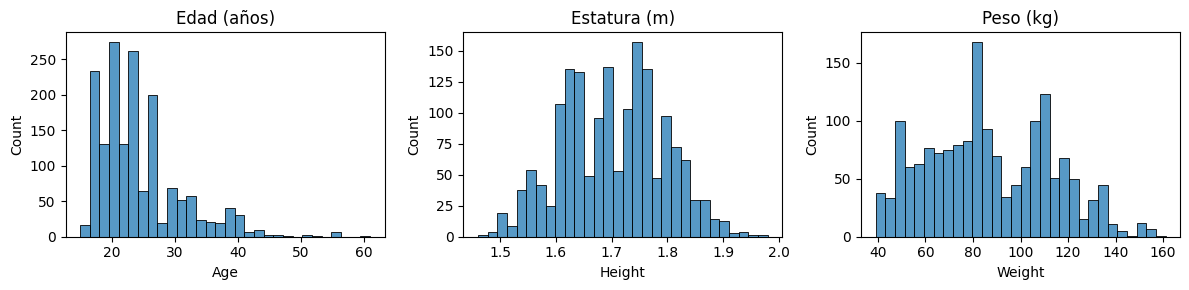

,Age,Height,Weight
count,1671.00,1671.00,1671.00
mean,24.43,1.70,86.83
std,6.48,0.09,26.15
min,15.00,1.46,39.00
25%,20.00,1.63,65.50
50%,23.00,1.70,83.00
75%,26.00,1.77,109.00
max,61.00,1.98,161.00


In [12]:
# Edad, estatura y peso: resumen estadístico e histogramas
continuas = ["Age", "Height", "Weight"]
figura, ejes = plt.subplots(1, 3, figsize=(12, 3))
for eje, variable in zip(ejes, continuas):
    sns.histplot(train[variable], bins=30, ax=eje)
    eje.set_title(DESCRIPCION[variable])
plt.tight_layout()
plt.show()
train[continuas].describe().round(2)

**Qué observamos:** la edad va de 15 a 61 años en el train, con mediana de 23: la muestra es joven. El peso va de 39 a 161 kg y la estatura de 1.46 a 1.98 m. No hay valores imposibles.

In [13]:
# Respuestas de la encuesta (ya redondeadas) y variables categóricas: frecuencia de cada valor
for variable in utilidades.ENCUESTA_OBESIDAD + ["CAEC", "CALC", "MTRANS"]:
    print(variable, train[variable].value_counts().to_dict())

FCVC {3.0: 794, 2.0: 791, 1.0: 86}
NCP {3.0: 1166, 1.0: 233, 2.0: 141, 4.0: 131}
CH2O {2.0: 916, 3.0: 421, 1.0: 334}
FAF {1.0: 596, 0.0: 572, 2.0: 413, 3.0: 90}
TUE {0.0: 753, 1.0: 725, 2.0: 193}
CAEC {'Sometimes': 1420, 'Frequently': 178, 'Always': 42, 'no': 31}
CALC {'Sometimes': 1091, 'no': 524, 'Frequently': 56}
MTRANS {'Public_Transportation': 1243, 'Automobile': 370, 'Walking': 45, 'Motorbike': 9, 'Bike': 4}


**Qué observamos:** tras el redondeo, cada respuesta toma pocos valores, como en el cuestionario original (por ejemplo, FAF entre 0 y 3). Hay niveles muy poco frecuentes: CAEC = "no" (31 filas), MTRANS = Bike (4) y Motorbike (9). CALC = "Always" ya no aparece porque se fusionó con "Frequently" (tenía una sola fila).

## 5. Análisis multivariante y trampas del dataset

**Qué hacemos:** verificamos las trampas documentadas: cuánto de cada clase es sintético, el sexo por clase, la relación del target con el IMC, los menores de edad y las filas repetidas.

**Por qué:** cada trampa condiciona una decisión: los escenarios con y sin estatura y peso, el redondeo, la partición agrupada, la interpretación de Gender y la discusión ética. La figura 3 usa todas las filas porque describe una propiedad del dataset que justifica un paso aplicado antes de dividir; el resto usa solo el train.

In [14]:
# Proporción de filas probablemente reales y de mujeres en cada clase (todas las filas)
por_clase = datos.groupby(OBJETIVO).agg(
    filas=(OBJETIVO, "size"),
    proporcion_real=("probablemente_real", "mean"),
    proporcion_mujeres=("Gender", lambda g: (g == "Female").mean())).reindex(ORDEN)
por_clase.round(2)

,filas,proporcion_real,proporcion_mujeres
NObeyesdad,,,
Insufficient_Weight,267,0.13,0.63
Normal_Weight,282,1.00,0.49
Overweight_Level_I,276,0.20,0.53
Overweight_Level_II,290,0.20,0.36
Obesity_Type_I,351,0.13,0.44
Obesity_Type_II,297,0.04,0.01
Obesity_Type_III,324,0.01,1.00


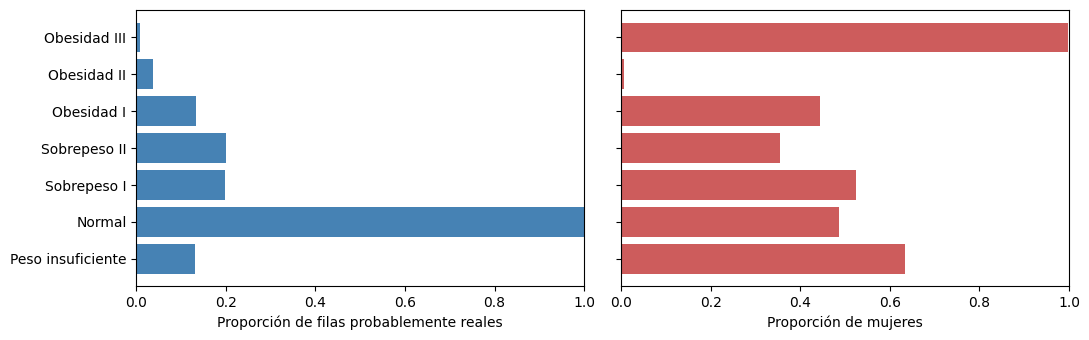

In [15]:
# Figura 3: huella sintética y sexo por clase
etiquetas = [NOMBRES_CLASES[c] for c in ORDEN]
figura, ejes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
ejes[0].barh(etiquetas, por_clase["proporcion_real"], color="steelblue")
ejes[0].set_xlabel("Proporción de filas probablemente reales")
ejes[1].barh(etiquetas, por_clase["proporcion_mujeres"], color="indianred")
ejes[1].set_xlabel("Proporción de mujeres")
for eje in ejes:
    eje.set_xlim(0, 1)
    eje.invert_yaxis()
plt.tight_layout()
utilidades.guardar_figura(figura, "figura_03_huella_sintetica_obesidad")
plt.show()

**Qué observamos:** la proporción de filas reales cambia drásticamente entre clases: Normal_Weight es 100% real y Obesity_Type_III solo 1% (3 de 324 filas). Por eso los decimales de SMOTE delatan la clase y hay que redondear (diseño, §4.1). El sexo por clase confirma el artefacto documentado: Obesity_Type_II es 99% de hombres y Obesity_Type_III 100% de mujeres. Con tan pocas filas reales de partida, SMOTE replicó el sexo de unas pocas personas. Un modelo puede aprender a separar estas dos clases por el sexo, lo que es un sesgo espurio que se revisa en la interpretación y en la Discusión ética.

In [16]:
# IMC = peso / estatura² en el train: rango por clase (el target se definió con el IMC)
imc = train["Weight"] / train["Height"] ** 2
rangos = imc.groupby(train[OBJETIVO]).agg(["min", "median", "max"]).reindex(ORDEN)
rangos.round(1)

,min,median,max
NObeyesdad,,,
Insufficient_Weight,13.1,17.6,19.3
Normal_Weight,18.5,22.0,24.9
Overweight_Level_I,22.9,26.0,28.7
Overweight_Level_II,25.5,28.1,30.4
Obesity_Type_I,29.8,32.1,35.2
Obesity_Type_II,33.9,36.4,39.7
Obesity_Type_III,36.8,42.2,50.8


**Qué observamos:** el target se definió a partir del IMC: cada clase ocupa una franja ordenada de valores, desde una mediana de 17.6 en Insufficient_Weight hasta 42.2 en Obesity_Type_III. Por eso en E1, con estatura y peso, el problema se reduce a reconstruir el IMC. Las franjas se solapan en sus bordes (por ejemplo, Overweight_Level_I llega a 28.7 y Overweight_Level_II empieza en 25.5), así que ni siquiera E1 permite una clasificación perfecta.

In [17]:
# Menores de 18 años en el train y su distribución por clase
menores = train[train["Age"] < 18]
print("Menores de 18 años en el train:", len(menores), f"({len(menores) / len(train):.1%})")
print("De ellos, probablemente reales:", menores["probablemente_real"].sum())
print(menores[OBJETIVO].value_counts().reindex(ORDEN).fillna(0).astype(int).to_dict())

Menores de 18 años en el train: 78 (4.7%)
De ellos, probablemente reales: 32
{'Insufficient_Weight': 30, 'Normal_Weight': 20, 'Overweight_Level_I': 16, 'Overweight_Level_II': 5, 'Obesity_Type_I': 7, 'Obesity_Type_II': 0, 'Obesity_Type_III': 0}


**Qué observamos:** el train tiene 78 menores de 18 años (4.7%), de los cuales solo 32 parecen reales. Se concentran en las clases de menor peso y ninguno está en Obesity_Type_II ni en Obesity_Type_III. Los umbrales de IMC del target son los de adultos y no se aplican directamente a adolescentes; se conservan las filas y se discute en la sección ética (diseño, §15.3).

In [18]:
# Filas repetidas (mismo vector sin estatura ni peso): proporción por clase en el train
tamano_grupo = train.groupby("grupo")["grupo"].transform("size")
repetidas = (tamano_grupo > 1).groupby(train[OBJETIVO]).mean().reindex(ORDEN)
print("Grupo más grande del train:", tamano_grupo.max(), "filas idénticas")
repetidas.round(2)

Grupo más grande del train: 75 filas idénticas


NObeyesdad
Insufficient_Weight    0.41
Normal_Weight          0.04
Overweight_Level_I     0.28
Overweight_Level_II    0.28
Obesity_Type_I         0.46
Obesity_Type_II        0.63
Obesity_Type_III       0.97
Name: grupo, dtype: float64

**Qué observamos:** tras el redondeo, el 97% de las filas de Obesity_Type_III del train repiten exactamente el vector de otra fila (sin contar estatura ni peso), y el grupo más grande reúne 75 filas idénticas. En Normal_Weight, que es real, solo el 4% se repite. Sin partición agrupada, el modelo vería en el test copias de lo que memorizó en el train.

In [19]:
# Asociación de cada variable categórica u ordinal con el target: chi² (curso) y V de Cramér
from scipy.stats import chi2_contingency

filas = []
for variable in utilidades.BINARIAS_OBESIDAD + ["MTRANS", "CAEC", "CALC"] + utilidades.ENCUESTA_OBESIDAD:
    tabla = pd.crosstab(train[variable], train[OBJETIVO])
    chi2, p_valor, _, _ = chi2_contingency(tabla)
    v_cramer = (chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))) ** 0.5
    filas.append({"variable": variable, "chi2": round(chi2, 1), "p_valor": p_valor, "v_cramer": round(v_cramer, 3)})
asociacion = pd.DataFrame(filas).sort_values("v_cramer", ascending=False)
asociacion

,variable,chi2,p_valor,v_cramer
0,Gender,525.5,2.662561e-110,0.561
1,family_history_with_overweight,482.6,4.739881e-101,0.537
8,FCVC,441.2,6.822876e-87,0.363
2,FAVC,193.5,4.626064e-39,0.340
6,CAEC,560.5,1.901231e-107,0.334
9,NCP,438.4,8.612594e-82,0.296
7,CALC,272.5,2.680293e-51,0.286
4,SCC,102.1,9.361068e-20,0.247
11,FAF,237.1,3.370041e-40,0.217
10,CH2O,148.1,1.381369e-25,0.211


**Qué observamos:** las variables más asociadas con el nivel de obesidad son Gender (V de Cramér 0.56) y family_history_with_overweight (0.54). La asociación de Gender es en buena parte un artefacto del sobremuestreo (figura 3). Entre los hábitos, destacan el consumo de verduras (FCVC, 0.36), los alimentos hipercalóricos (FAVC, 0.34) y comer entre comidas (CAEC, 0.33). SMOKE es la menos asociada.

## 6. Valores atípicos (diagnóstico)

**Qué hacemos:** aplicamos la regla IQR a la edad, la estatura y el peso, e Isolation Forest sobre las variables numéricas y ordinales.

**Por qué:** son técnicas del curso; aquí sirven solo como diagnóstico. No se eliminan filas (diseño, §4.2).

In [20]:
# Regla IQR: filas del train fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]
q1, q3 = train[continuas].quantile(0.25), train[continuas].quantile(0.75)
rango = q3 - q1
fuera = (train[continuas] < q1 - 1.5 * rango) | (train[continuas] > q3 + 1.5 * rango)
pd.DataFrame({"filas_fuera": fuera.sum(), "limite_inferior": (q1 - 1.5 * rango).round(2),
              "limite_superior": (q3 + 1.5 * rango).round(2)})

,filas_fuera,limite_inferior,limite_superior
Age,127,11.00,35.00
Height,0,1.42,1.98
Weight,0,0.25,174.25


In [21]:
# Isolation Forest sobre las numéricas y ordinales (marca el 2% más aislado; solo diagnóstico)
from sklearn.ensemble import IsolationForest

NUMERICAS = continuas + utilidades.ENCUESTA_OBESIDAD
bosque = IsolationForest(contamination=0.02, random_state=utilidades.SEMILLA)
es_atipica = bosque.fit_predict(train[NUMERICAS]) == -1
print("Filas marcadas:", es_atipica.sum())
print("Clase de las marcadas:", train.loc[es_atipica, OBJETIVO].value_counts().to_dict())
train.loc[es_atipica, continuas].describe().round(2)

Filas marcadas: 34
Clase de las marcadas: {'Normal_Weight': 11, 'Obesity_Type_I': 7, 'Insufficient_Weight': 6, 'Overweight_Level_I': 5, 'Obesity_Type_II': 4, 'Overweight_Level_II': 1}


,Age,Height,Weight
count,34.00,34.00,34.00
mean,25.41,1.65,69.71
std,10.09,0.10,24.55
min,15.00,1.51,39.00
25%,19.00,1.57,50.00
50%,20.50,1.60,63.50
75%,29.75,1.77,93.50
max,55.00,1.84,112.00


**Qué observamos:** la regla IQR marca 127 filas por edad (mayores de 35 años) y ninguna por estatura ni por peso. Isolation Forest marca 34 filas (2%), repartidas entre varias clases y sin valores imposibles. Son combinaciones poco comunes, no errores, así que no se elimina ninguna fila.

## 7. Decisiones de preprocesamiento que se derivan

| Hallazgo (sección) | Decisión | Diseño |
|---|---|---|
| Sin faltantes; 24 duplicados exactos (2) | Se eliminan los duplicados antes de dividir | §4.1 |
| Decimales de SMOTE que delatan la clase (2 y 5) | Se redondea a la precisión de la encuesta | §4.1 |
| 97% de Obesity_Type_III son vectores repetidos (5) | Partición agrupada por vectores idénticos; test elegido por criterio estructural | §7 |
| Target definido por el IMC (5) | Dos escenarios: E1 con estatura y peso, E2 sin ellos (principal) | §1 |
| Clases casi balanceadas (4) | No se remuestrea | §5 |
| Target ordenado (4 y 5) | Kappa ponderado cuadrático junto al macro-F1 | §9 |
| Artefacto de género (5) | Se revisa el peso de Gender en la interpretación y se discute en ética | §10 |
| Menores de edad (5) | Se conservan; limitación ética y de validez | §15.3 |
| CALC = "Always" con 1 fila; MTRANS con niveles raros (4) | Fusión con "Frequently"; *one-hot* con agrupación de niveles raros | §4.1 y §4.2 |
| Atípicos plausibles (6) | No se eliminan filas | §4.2 |

## Guardar resultados en GitHub (solo corrida oficial en Colab)

**Qué hacemos:** subimos a `main` los archivos de `resultados/` que genera este notebook.

**Por qué:** las cifras del reporte deben salir de la misma corrida que deja las salidas visibles en el notebook (§12, regla 4). En VS Code esta celda no hace nada; Marcelo hace el *commit* desde VS Code. Después de esta celda, guardar el notebook con *File → Save a copy in GitHub*.

In [22]:
# Celda final. Cambiar a True solo en la corrida oficial, después de "Reiniciar y ejecutar todo".
import glob

GUARDAR_EN_GITHUB = False
PATRONES_DE_ESTE_NOTEBOOK = ["resultados/tablas/tabla_01_*obesidad.csv", "resultados/figuras/figura_0[23]_*obesidad.png"]
if EN_COLAB and GUARDAR_EN_GITHUB:
    archivos = " ".join(f for patron in PATRONES_DE_ESTE_NOTEBOOK for f in sorted(glob.glob(patron)))
    nombre, correo = userdata.get("GITHUB_NOMBRE"), userdata.get("GITHUB_CORREO")
    !git config user.name "{nombre}"
    !git config user.email "{correo}"
    !git add {archivos}
    !git commit -q -m "03-obesidad: actualiza resultados de la corrida oficial"
    !git pull -q --rebase
    !git push -q
    print("Archivos subidos:", archivos)